In [1]:
%load_ext autoreload
%autoreload 2

# Fine-tuning a Pre-trained Model for Single-Cell Multi-Omics Integration
This notebook demonstrates how to fine-tune a pre-trained scPMMI model for paired single-cell multi-omics integration (RNA + ATAC).
The example uses a 10x Multiome PBMC dataset where each cell contains both RNA and ATAC measurements.

We summarize the fine-tuning pipeline in the following steps, which can be used as general recipe for fine-tuning on multi-omics integration task and beyond:

    1. Specify hyper-parameter setup for multi-omics integration
    2. Load and pre-process data
    3. Load the pre-trained scPMMI model
    4. fine-tune scPMMI with task-specific objectives
    5. Evaluate fine-tuned scPMMI

In [2]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings('ignore')

import os
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import muon as mu
import scanpy as sc
import muon as mu
import random
from tqdm import tqdm
from typing import Tuple
from scipy.sparse import issparse
import swanlab
import matplotlib.pyplot as plt

import torch
from torch import optim, Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torch.amp.autocast_mode import autocast
from transformers.optimization import get_scheduler

from scpmmi.utils.unify import align_to_common_peaks, align_to_common_genes
from scpmmi.tokenizer.vocab import Vocab
from scpmmi.models.scPMMI import scPMMI
from scpmmi.loss import ContrastiveLoss
from scpmmi.utils.util import set_seed 
from scpmmi import logger

## Step 1: Specify hyperparameter setup for the integration task
This section defines the default hyperparameters used for fine-tuning. The values are collected into a single configuration dictionary that is passed to experiment tracking.

In [3]:
hyperparameter_defaults = dict(
    task='multiomics',
    seed=42,
    dataset_name='10x_multiome_pbmc_10k',
    data_path='../data/mdata/rna_atac/10x_multiome_pbmc_10k.h5mu',
    load_model = '../ckpt/ckpt_epitra',
    gene_vocab='../config_file/default_gene_vocab.json',
    peak_vocab='../config_file/default_peak_vocab.json',
    batch_size=64,
    num_workers=4,
    temperature=0.01,
    alpha=1.5,
    n_epochs=10,
    lr=1e-4,
    weight_decay=0.05,
)

In [4]:
run = swanlab.init(
    project="scPMMI-fine-tuning",
    experiment_name=f"fine-tuning-{time.strftime('%b%d-%H-%M')}",
    config=hyperparameter_defaults,
    reinit=True,
)
config = run.config
set_seed(config.seed)

swanlab: Tracking run with swanlab version 0.6.8

swanlab: Run data will be saved locally in 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_205018-pib690epkscjasoccvedw

swanlab: 👋 Hi zhenyuan,welcome to swanlab!

swanlab: Syncing run fine-tuning-Jan25-20-50 to the cloud

swanlab: 🏠 View project at https://swanlab.cn/@zhenyuan/scPMMI-fine-tuning

swanlab: 🚀 View run at https://swanlab.cn/@zhenyuan/scPMMI-fine-tuning/runs/pib690epkscjasoccvedw

In [5]:
dataset_name = config.dataset_name
save_path = Path(f"./result/multiome_integration_epitra/dev_{dataset_name}-{time.strftime('%b%d-%H-%M')}/")
save_path.mkdir(parents=True, exist_ok=True)
print(f"save to {save_path}")

save to result/multiome_integration_epitra/dev_10x_multiome_pbmc_10k-Jan25-20-50


## Step 2: Load and pre-process data
This step shows how to read the input multi-modal dataset and run modality-specific preprocessing so that inputs match the pre-trained model's expected token and value formats.
Key goals:
- Read paired RNA/ATAC data from `.h5mu` or `.h5` files.
- Ensure consistent batch annotations and compute integer batch IDs used by the model.
- Apply modality transforms (log1p normalization for RNA; binary thresholding for ATAC) used during pretraining.

### 2.1 Load raw data
Load the dataset into a `muon` MultiData object and extract the RNA and ATAC `AnnData` modules. The code handles `.h5mu` and `.h5` formats and ensures a `batch` column exists in `adata_rna.obs`.

In [6]:
if config.data_path.endswith(".h5mu"):
    mdata = mu.read_h5mu(config.data_path)
elif config.data_path.endswith(".h5"):
     mdata = mu.read_10x_h5(config.data_path)
else:
    raise ValueError(f"Unsupported file format: {config.data_path}")
adata_rna = mdata.mod['rna']
adata_atac = mdata.mod['atac'] 
if 'batch' not in adata_rna.obs.columns:
    adata_rna.obs['batch'] = '0'
    adata_atac.obs['batch'] = '0'
adata_rna.obs["str_batch"] = adata_rna.obs["batch"].astype(str)
batch_id_labels = adata_rna.obs["str_batch"].astype("category").cat.codes.values
adata_rna.obs["batch_id"] = batch_id_labels
adata_rna

AnnData object with n_obs × n_vars = 9631 × 36601
    obs: 'cell_type', 'batch', 'str_batch', 'batch_id'
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

### 2.2 Align genes and peaks to the pre-trained model vocabulary
A pre-trained model expects a fixed token vocabulary for genes and peaks. Use the provided `Vocab` files to map your dataset's features to the pretrained token order.
Steps performed by the code below:
- Load `gene_vocab` and `peak_vocab` from JSON files used during pretraining.
- Filter and reorder `adata_rna` and `adata_atac` so that feature indices match the model tokens.

In [7]:
gene_vocab = Vocab.from_file(config.gene_vocab)
gene_list = gene_vocab.get_token_list()
gene_ids = gene_vocab(gene_list)
adata_rna = align_to_common_genes(adata_rna, gene_list)    

2026-01-25 20:50:21 - scPMMI - INFO - Number of matched genes: 23151


In [8]:
peak_vocab = Vocab.from_file(config.peak_vocab)
peak_list = peak_vocab.get_token_list()
peak_ids = peak_vocab(peak_list)
adata_atac = align_to_common_peaks(adata_atac, peak_list)

2026-01-25 20:50:36 - scPMMI - INFO - Number of matched peaks: 40885


## Step 3: Load the pre-trained scPMMI model
Load model architecture and weights from a checkpoint directory. The code sets the target device and dtype and supports partial checkpoint loading when the saved state dict does not exactly match the model (useful for architecture changes or fine-tuning variants).

In [9]:
device = 'cuda:1'
torch.cuda.set_device(device)
dtype = torch.bfloat16
model_dir = Path(config.load_model)
model_config_file = model_dir / "config.json"
model_ckpt = model_dir / "model.bin"
with open(model_config_file, "r") as f:
    model_config = json.load(f)
model = scPMMI(
    model_config,
    do_mvc=True,
    do_dab=True,
    use_batch_labels=True,
    num_batch_labels=len(set(batch_id_labels)),
)
if config.load_model is not None:
    try:
        model.load_state_dict(torch.load(model_ckpt))
        logger.info(f"Loading all model params from {model_ckpt}")
    except:
        # only load params that are in the model and match the size
        model_dict = model.state_dict()
        pretrained_dict = torch.load(model_ckpt)
        pretrained_dict = {
            k: v
            for k, v in pretrained_dict.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
        for k, v in pretrained_dict.items():
            logger.info(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model = model.to(device, dtype)

2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.cls_token with shape torch.Size([1, 1, 512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.patch_position_embeddings with shape torch.Size([1, 160, 512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.embedding.weight with shape torch.Size([40957, 512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.norm.weight with shape torch.Size([512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.weight with shape torch.Size([1536, 512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.bias with shape torch.Size([1536])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.out_proj.weight with shape torch.Size([512, 512])
2026-01-25 20:51:34 - scPMMI - INFO - Loading params

## Step 4: Fine-tune the model with task-specific objectives
This section defines the training dataset, losses, optimizer, and the fine-tuning loop. The training objective combines a contrastive (CLIP-style) loss on paired cell embeddings with reconstruction losses for each modality (MSE for RNA, BCE for ATAC).
Key components:
- `MultiSeqDataset`: prepares paired token ids and preprocessed value matrices for RNA and ATAC, including binarization for ATAC and log-normalization for RNA.
- `ContrastiveLoss`: pulls together RNA/ATAC cell embeddings for the same cell and separates different cells in embedding space.
- Reconstruction losses: MSE for continuous RNA reconstructions, BCE for binary ATAC reconstructions. We sum these with the contrastive loss to form the final objective.
- Training loop: use automatic mixed precision (bfloat16 here), AdamW optimizer, and a cosine learning rate scheduler with warmup. Log metrics to `swanlab` for experiment tracking.

In [10]:
class MultiSeqDataset(Dataset):
    def __init__(
        self,
        adata_mod1: sc.AnnData,
        feature_ids_mod1: list,
        adata_mod2: sc.AnnData,
        feature_ids_mod2: list,
        batch_id_labels,
        dtype=torch.float32
    ):
        self.feature_ids_mod1 = torch.tensor(feature_ids_mod1, dtype=torch.int32)
        self.feature_ids_mod2 = torch.tensor(feature_ids_mod2, dtype=torch.int32)
        batch_id_labels = torch.tensor(batch_id_labels, dtype=torch.long)
        # ---------------------- Process first modality ----------------------
        X_rna_input = adata_mod1.X.toarray() if issparse(adata_mod1.X) else adata_mod1.X # type: ignore
        X_rna_input = torch.tensor(X_rna_input, dtype=dtype)
        X_rna_input = torch.log1p(X_rna_input / X_rna_input.sum(1)[:, None] * 1e4)
        tokens_gene = self.feature_ids_mod1.unsqueeze(0).repeat(X_rna_input.size(0), 1)

        # ---------------------- Process second modality ----------------------
        atac_input = adata_mod2.X.toarray() if issparse(adata_mod2.X) else adata_mod2.X # type: ignore
        atac_input = torch.tensor(atac_input, dtype=dtype)
        X_atac_input = (atac_input > 0).float()

        tokens_peak = self.feature_ids_mod2.unsqueeze(0).repeat(atac_input.size(0), 1)
        # ---------------------- Store both modalities ----------------------
        self.data = {
            "mod1_token_ids": tokens_gene,
            "mod1_values": X_rna_input,
            "mod1_values_target": X_rna_input,

            "mod2_token_ids": tokens_peak,
            "mod2_values": X_atac_input,
            "mod2_values_target": X_atac_input,

            "batch_id": batch_id_labels
        }

    def __len__(self):
        return self.data["mod1_token_ids"].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.data.items()}

In [11]:
dataset = MultiSeqDataset(adata_rna, gene_ids, adata_atac, peak_ids, batch_id_labels)

data_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)

In [12]:
criterion = ContrastiveLoss(
    temperature=config.temperature, alpha=config.alpha
)
criterion_mse = nn.MSELoss()
criterion_bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(10))
optimizer = optim.AdamW( # type: ignore
    model.parameters(), lr=config.lr, weight_decay=config.weight_decay
)
max_train_steps = config.n_epochs * len(data_loader)
num_warmup_steps = int(0.1 * max_train_steps)  # 10% steps for warmup
scheduler = get_scheduler(
    name="cosine",
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=max_train_steps,
)

In [13]:
model.train()
global_step = 0
for epoch in range(config.n_epochs):
    loop = tqdm(data_loader, desc=f'Epoch [{epoch}/{config.n_epochs}]',leave=False)
    for step, batch_data in enumerate(loop):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)
        mod1_values_target = batch_data["mod1_values_target"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)
        batch_ids = batch_data["batch_id"].to(device)

        optimizer.zero_grad()
        with autocast(device_type="cuda", dtype=dtype):
            output = model(
                mod1_token_ids, mod1_values_input, 
                mod2_token_ids, mod2_values_input,
                batch_ids,
                MVC=True,
            )
            metric_to_log = {}
            loss_clip = criterion(output['cell_emb_mod1'], output['cell_emb_mod2'])
            loss = loss_clip
            metric_to_log['clip'] = loss_clip.item()

            loss_mse = criterion_mse(output['mvc_output_mod1'], mod1_values_target.to(output['mvc_output_mod1']))
            loss_bce = criterion_bce(output['mvc_output_mod2'], mod2_values_target.to(output['mvc_output_mod2']))
            loss += loss_mse + loss_bce
            metric_to_log['mvc_mse'] = loss_mse.item()
            metric_to_log['mvc_bce'] = loss_bce.item()

        metric_to_log['loss'] = loss.item()
        metric_to_log['step'] = global_step
        metric_to_log['lr'] = scheduler.get_last_lr()[0]
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loop.set_postfix(metric_to_log)
                    
        swanlab.log(metric_to_log)

Epoch [0/10]:   0%|          | 0/151 [00:00<?, ?it/s]

In [14]:
model.save_pretrained(save_path / 'ckpt')

## Step 5: Inference, visualization, and evaluation
After fine-tuning, set the model to evaluation mode and run inference to extract cell embeddings for both modalities. 
Evaluation workflow:
- Extract embeddings for all cells using the same preprocessing as training.
- Build an `AnnData` object for visualization (UMAP).
- Compute biological conservation and batch correction metrics

In [15]:
model.eval()        
test_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                        num_workers=config.num_workers, pin_memory=True)
with torch.no_grad():
    cell_emb_rna, cell_emb_atac = [], []
    for batch_data in tqdm(test_loader, desc="Inference"):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)
        mod1_values_target = batch_data["mod1_values_target"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)
        batch_ids = batch_data["batch_id"].to(device)

        output = model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input, batch_ids)
        cell_emb_rna.append(output['cell_emb_mod1'].cpu())
        cell_emb_atac.append(output['cell_emb_mod2'].cpu())

    cell_emb_rna = torch.cat(cell_emb_rna, dim=0).to(torch.float32).numpy()
    cell_emb_atac = torch.cat(cell_emb_atac, dim=0).to(torch.float32).numpy()

    adata_rna.obs['modality'] = 'rna'
    adata_atac.obs['modality'] = 'atac'
    X = np.concatenate((cell_emb_rna, cell_emb_atac), axis=0)
    obs = pd.concat([adata_rna.obs, adata_atac.obs], ignore_index=True)
    concat_cell_emb = sc.AnnData(X=X, obs=obs)

Inference: 100%|██████████| 151/151 [00:12<00:00, 12.02it/s]


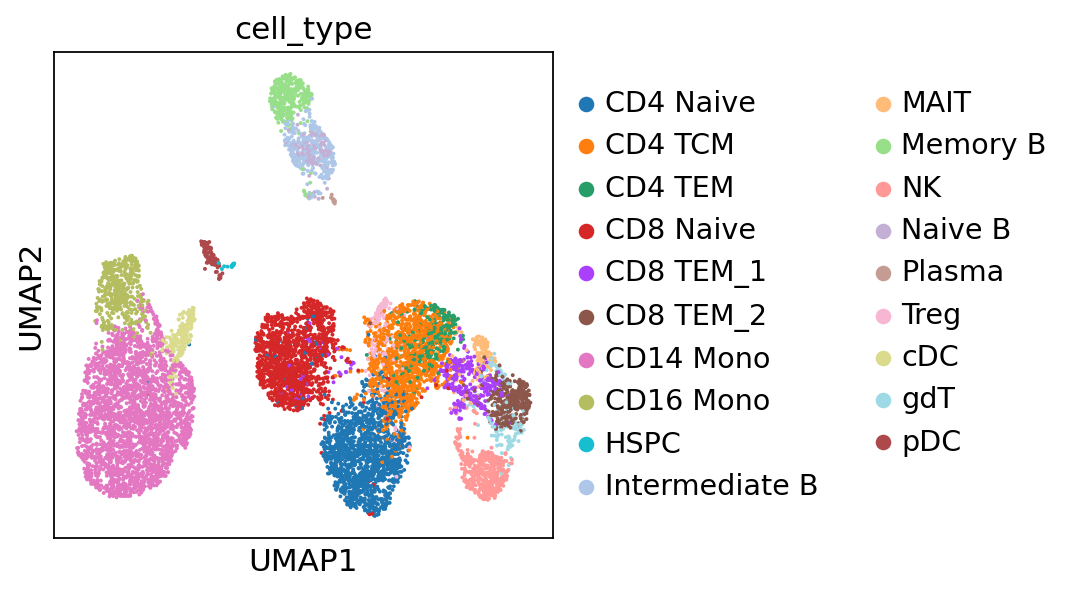

In [16]:
sc.set_figure_params(figsize=(4, 4))
cell_emb_rna = concat_cell_emb[concat_cell_emb.obs['modality'] == 'rna'].X
cell_emb_atac = concat_cell_emb[concat_cell_emb.obs['modality'] == 'atac'].X
emb = cell_emb_rna
obs = concat_cell_emb[concat_cell_emb.obs['modality'] == 'rna'].obs
EmbAdata = sc.AnnData(X=emb, obs=obs)
sc.pp.neighbors(EmbAdata)

sc.tl.umap(EmbAdata, min_dist=0.5, spread=1.0)
if 'batch' in EmbAdata.obs.columns and len(set(EmbAdata.obs['batch'].unique())) > 1:
    sc.pl.umap(EmbAdata, color=['batch', 'cell_type'], ncols=2, wspace=0.3)
else:
    sc.pl.umap(EmbAdata, color=['cell_type'], ncols=2, wspace=0.3)
EmbAdata.write(save_path / "cell_emb.h5ad")

In [ ]:
from scpmmi.utils.metrics import biology_conservation
metrics = {}
biology_conservation_metrics, best_res= biology_conservation(
    EmbAdata, EmbAdata.obs['cell_type'].values, start=20, end=40, scale=100
)
metrics['BioCons'] = round(float(np.mean(list(biology_conservation_metrics.values()))), 3)
biology_conservation_metrics = {k: round(float(v), 3) for k, v in biology_conservation_metrics.items()}
metrics.update(biology_conservation_metrics)
metrics

{'BioCons': 0.801,
 'ARI': 0.836,
 'NMI': 0.838,
 'Mean average precision': 0.87,
 'ASW_celltype': 0.662}

In [18]:
from scpmmi.utils.metrics import batch_correct
if 'batch' in EmbAdata.obs.columns and len(set(EmbAdata.obs['batch'].unique())) > 1:
    batch_correct_metrics = batch_correct(
        EmbAdata, EmbAdata.obs['cell_type'].values, EmbAdata.obs['batch'].values
    )
    metrics['BatchCorr'] = round(float(np.mean(list(batch_correct_metrics.values()))), 3)
    batch_correct_metrics = {k: round(float(v), 3) for k, v in batch_correct_metrics.items()}
    metrics.update(batch_correct_metrics)
metrics

{'BioCons': 0.801,
 'ARI': 0.836,
 'NMI': 0.838,
 'Mean average precision': 0.87,
 'ASW_celltype': 0.662}

In [19]:
if not os.path.exists(f'{save_path}/metrics.csv'):
    metrics_df = pd.DataFrame([metrics])
else:
    metrics_df = pd.read_csv(
        f'{save_path}/metrics.csv' 
    )
    new_metrics_df = pd.DataFrame([metrics])
    metrics_df = pd.concat([metrics_df, new_metrics_df], ignore_index=True)
metrics_df.to_csv(f'{save_path}/metrics.csv', index=False)